# To Gossip or Not To Gossip: The Evolution of Cooperation Under Horizontal Gene Transfer

**Authors:** Ananya, Shrayansh, Yogesh  
**Affiliation:** Behavior, Evolution, Emergence 2026 (BEE 2026), The Institute of Mathematical Sciences (IMSc), Chennai  
**Date:** June 20, 2026  
**Repository:** [The-Evolution-of-Cooperation-Under-Horizontal-Gene-Transfer](https://github.com/tshrayansh/The-Evolution-of-Cooperation-Under-Horizontal-Gene-Transfer)

---

## Executive Summary & Biological Context

Horizontal Gene Transfer (HGT) is the lateral transfer of genetic material between unicellular organisms without reproduction. Despite its high biological cost:
1. **Donor Burden:** Donors synthesize extensive conjugation machinery (Type IV secretion system pilus, relaxosome complex, ATP consumption).
2. **Altruistic Sharing:** Donors transfer advantageous genetic material to potential competitors.

Yet, over **80% of bacterial genomes** across history have been acquired through HGT. Why is HGT so pervasive when individual selection strongly penalizes costly gene donation?

This project systematically reconstructs the mathematical framework presented at **BEE 2026 (IMSc)** to explore the evolutionary dynamics of HGT in the context of a **bacterial public goods game** (e.g., siderophore secretion). We formulate, simulate, and analyze four progressive mathematical models:

1. **Base Model:** Standard replicator-conjugation dynamics with costs of cooperation ($f_c$) and HGT ($f_s$).
2. **Independent Beneficial Plasmid Model:** Universal fitness gain ($f_+$) carried on a mobile plasmid across 8 bacterial phenotypes.
3. **Dependent Beneficial Plasmid Model:** Conditional fitness gain ($f_+$) tied specifically to the cooperative phenotype across 6 bacterial phenotypes.
4. **Plasmid-Chromosome Synergy Model:** Direct positive epistasis ($f_{pc}$) between chromosomal HGT machinery and the cooperative plasmid.

---


In [1]:
import numpy as np
import scipy.integrate as spi
import matplotlib.pyplot as plt

# Global Typography & Clean Aesthetic Configuration (Zero-Overlap Guaranteed)
plt.rcParams.update({
    "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.titleweight": "bold",
    "figure.dpi": 150,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.edgecolor": "#444444",
    "axes.linewidth": 1.0,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "grid.color": "#999999"
})

# Strictly Unified Color Palette
COLOR_GC = "#1a5fb4"        # Generous Cooperator (Cobalt Blue)
COLOR_GC_MINUS = "#62a0ea"  # Plasmid-free GC (Light Blue)
COLOR_GD = "#e66100"        # Generous Defector (Amber Orange)
COLOR_GD_MINUS = "#f69846"  # Plasmid-free GD (Light Orange)
COLOR_SC = "#26a269"        # Secretive Cooperator (Forest Green)
COLOR_SC_MINUS = "#57e389"  # Plasmid-free SC (Mint Green)
COLOR_SC_PLUS = "#8e24aa"   # Plasmid-bearing SC (Vibrant Purple)
COLOR_SD = "#c01c28"        # Secretive Defector (Crimson Red)
COLOR_SD_PLUS = "#681313"   # Plasmid-bearing SD (Deep Maroon)

# Shading tones
SHADE_SD = "#ffebee"        # Soft Red
SHADE_COEX = "#fff9c4"      # Soft Amber
SHADE_SC_PLUS = "#f3e5f5"   # Soft Purple
SHADE_GC = "#e3f2fd"        # Soft Blue

print("Simulation environment and styling system loaded successfully.")


Simulation environment and styling system loaded successfully.


---
## 1. Model 1: The Base Model (Slides 7–10)

### 1.1 Strategy Space & Normalization
The bacterial population is partitioned across two binary traits:
- **HGT Strategy:** Generous ($G$, performs HGT) vs. Secretive ($S$, does not perform HGT).
- **Social Strategy:** Cooperator ($C$, produces public goods at cost $f_c$) vs. Defector ($D$, exploits public goods).

This yields four strategies with population fractions:
$$x = [GC, GD, SC, SD]^\top, \quad \sum_{i} x_i = GC + GD + SC + SD = 1$$

### 1.2 Fitness Definitions
Let the baseline fitness be $1$.
- $GC$ pays both the cooperation cost $f_c$ and the HGT cost $f_s$:
  $$f_{GC} = 1 - f_c$$
- $GD$ avoids the cooperation cost but performs HGT:
  $$f_{GD} = 1$$
- $SC$ pays the cooperation cost but avoids the HGT cost (earning the relative advantage $f_s$):
  $$f_{SC} = 1 + f_s - f_c$$
- $SD$ pays neither cost, reaping the HGT savings without cooperative investment:
  $$f_{SD} = 1 + f_s$$

### 1.3 Mean Population Fitness
The mean fitness $\bar{f} = \sum_{i} x_i f_i$:
$$\begin{aligned}
\bar{f} &= GC(1 - f_c) + GD(1) + SC(1 + f_s - f_c) + SD(1 + f_s) \\
&= (GC + GD + SC + SD) - f_c(GC + SC) + f_s(SC + SD) \\
&= 1 - f_c(GC + SC) + f_s(SC + SD)
\end{aligned}$$

### 1.4 Conjugation Kinetics & Replicator Dynamics
Conjugation is donor-driven by generous cooperators ($GC$):
1. $GC + SD \xrightarrow{\alpha} GC + SC$ (Rate: $\alpha \cdot GC \cdot SD$)
2. $GC + GD \xrightarrow{\alpha} 2GC$ (Rate: $\alpha \cdot GC \cdot GD$)

The combined replicator-conjugation differential equations:
$$\begin{aligned}
\dot{GC} &= (f_{GC} - \bar{f})GC + \alpha \cdot GC \cdot GD \\
\dot{GD} &= (f_{GD} - \bar{f})GD - \alpha \cdot GC \cdot GD \\
\dot{SC} &= (f_{SC} - \bar{f})SC + \alpha \cdot GC \cdot SD \\
\dot{SD} &= (f_{SD} - \bar{f})SD - \alpha \cdot GC \cdot SD
\end{aligned}$$

**Simplex Conservation Invariance:**
$$\sum_{i} \dot{x}_i = \sum_i (f_i - \bar{f})x_i + (\alpha GC GD - \alpha GC GD) + (\alpha GC SD - \alpha GC SD) = (\bar{f} - \bar{f}) + 0 = 0$$
Hence, the total population density is strictly conserved for all $t \ge 0$.


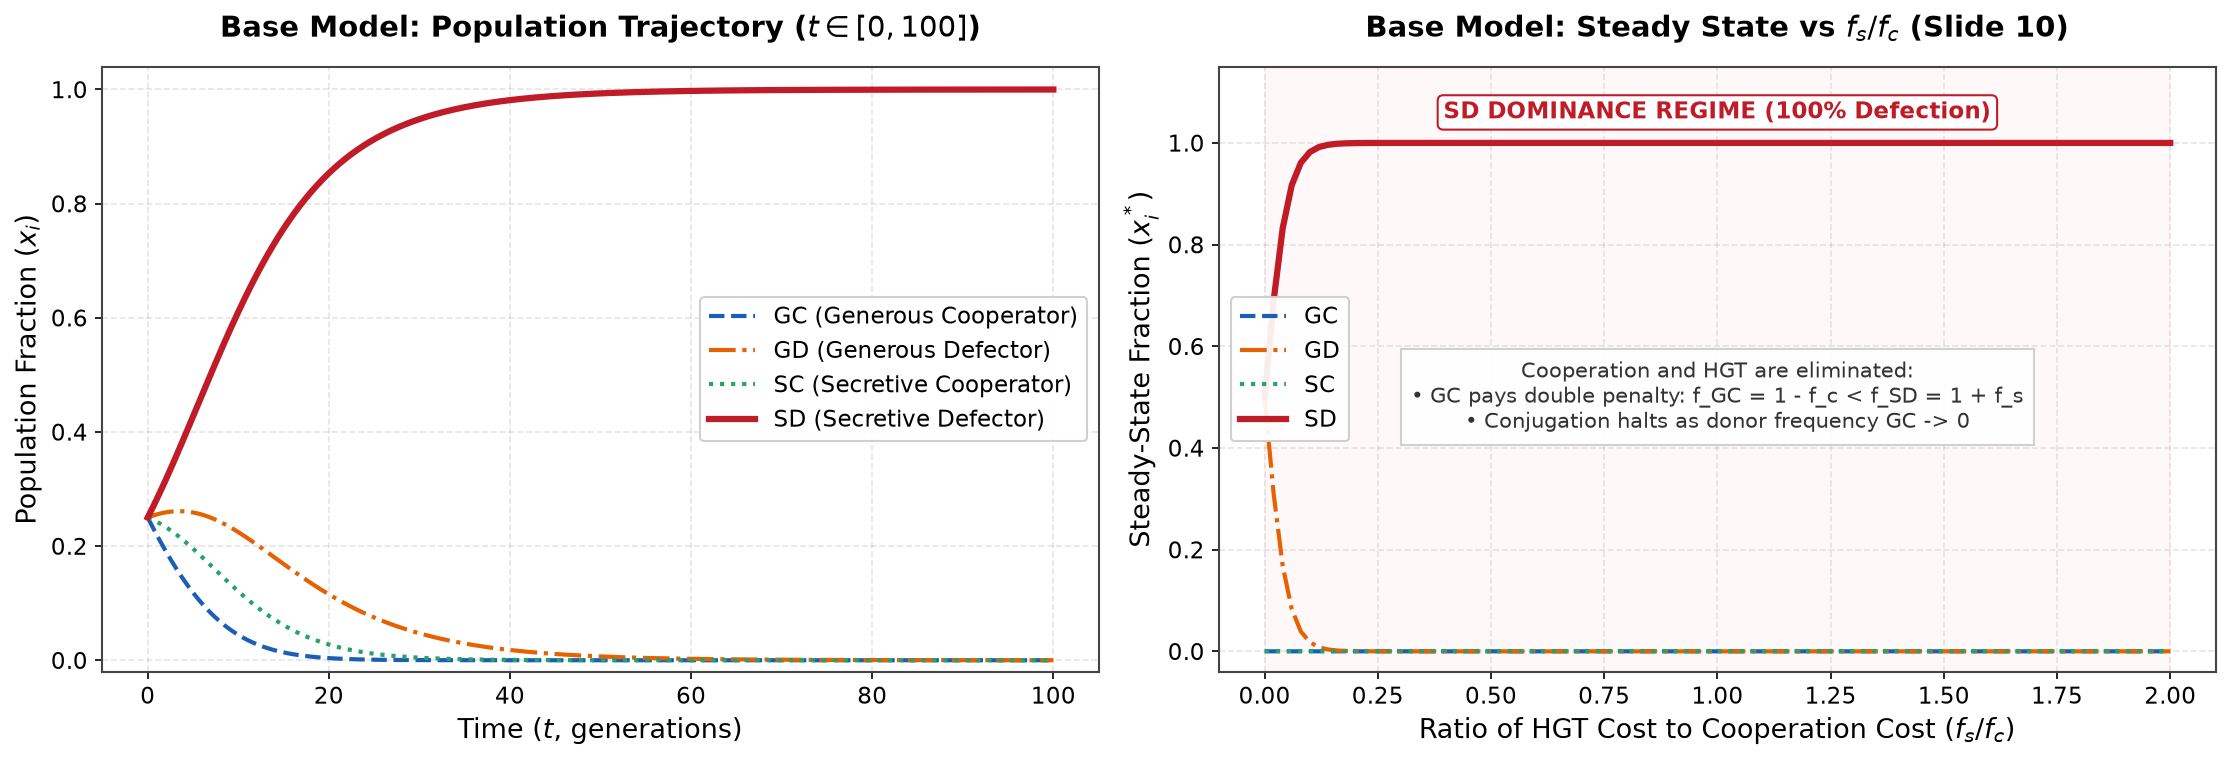

In [2]:
def base_model_ode(t, y, alpha, fc, fs):
    GC, GD, SC, SD = y
    f_GC = 1.0 - fc
    f_GD = 1.0
    f_SC = 1.0 + fs - fc
    f_SD = 1.0 + fs
    
    f_bar = 1.0 - fc * (GC + SC) + fs * (SC + SD)
    
    dGC = (f_GC - f_bar) * GC + alpha * GC * GD
    dGD = (f_GD - f_bar) * GD - alpha * GC * GD
    dSC = (f_SC - f_bar) * SC + alpha * GC * SD
    dSD = (f_SD - f_bar) * SD - alpha * GC * SD
    return [dGC, dGD, dSC, dSD]

# 1. Simulate time series
t_span = (0, 100)
t_eval = np.linspace(0, 100, 500)
y0 = [0.25, 0.25, 0.25, 0.25]
alpha = 0.1
fc = 0.2
fs = 0.1

sol_base = spi.solve_ivp(base_model_ode, t_span, y0, args=(alpha, fc, fs), t_eval=t_eval, method='RK45')

# 2. Parameter sweep vs fs / fc (Slide 10)
ratios = np.linspace(0.0, 2.0, 101)
base_sweep = []
for r in ratios:
    sol = spi.solve_ivp(base_model_ode, (0, 200), y0, args=(alpha, fc, r * fc), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    base_sweep.append(final / np.sum(final))
base_sweep = np.array(base_sweep)

# Clean, non-overlapping figure layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))

# Subplot 1: Trajectory
ax1.plot(sol_base.t, sol_base.y[0], label="GC (Generous Cooperator)", color=COLOR_GC, linestyle="--", linewidth=2.0)
ax1.plot(sol_base.t, sol_base.y[1], label="GD (Generous Defector)", color=COLOR_GD, linestyle="-.", linewidth=2.0)
ax1.plot(sol_base.t, sol_base.y[2], label="SC (Secretive Cooperator)", color=COLOR_SC, linestyle=":", linewidth=2.0)
ax1.plot(sol_base.t, sol_base.y[3], label="SD (Secretive Defector)", color=COLOR_SD, linestyle="-", linewidth=3.0)
ax1.set_title("Base Model: Population Trajectory ($t \\in [0, 100]$)", pad=14)
ax1.set_xlabel("Time ($t$, generations)")
ax1.set_ylabel("Population Fraction ($x_i$)")
ax1.set_ylim(-0.02, 1.04)
ax1.legend(loc="center right", framealpha=0.92)

# Subplot 2: Bifurcation (Slide 10)
ax2.plot(ratios, base_sweep[:, 0], label="GC", color=COLOR_GC, linestyle="--", linewidth=2.0)
ax2.plot(ratios, base_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.", linewidth=2.0)
ax2.plot(ratios, base_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":", linewidth=2.0)
ax2.plot(ratios, base_sweep[:, 3], label="SD", color=COLOR_SD, linestyle="-", linewidth=3.0)
ax2.axvspan(0.0, 2.0, color=SHADE_SD, alpha=0.35)
ax2.set_title("Base Model: Steady State vs $f_s / f_c$ (Slide 10)", pad=14)
ax2.set_xlabel(r"Ratio of HGT Cost to Cooperation Cost ($f_s / f_c$)")
ax2.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax2.set_ylim(-0.04, 1.15)
ax2.text(1.0, 1.06, "SD DOMINANCE REGIME (100% Defection)",
         ha="center", va="center", color=COLOR_SD, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=COLOR_SD, linewidth=1.0))
ax2.text(1.0, 0.50,
         "Cooperation and HGT are eliminated:\n"
         "• GC pays double penalty: f_GC = 1 - f_c < f_SD = 1 + f_s\n"
         "• Conjugation halts as donor frequency GC -> 0",
         ha="center", va="center", fontsize=10, color="#333333",
         bbox=dict(boxstyle="square,pad=0.5", facecolor="#ffffff", edgecolor="#cccccc", alpha=0.9))
ax2.legend(loc="center left", framealpha=0.92)

plt.tight_layout()
plt.show()


### Inferences from Base Model
- **Defector Dominance:** In the absence of spatial assortment, defectors exploit public goods with zero investment. Within each HGT class:
  $$f_{SD} - f_{SC} = f_c > 0, \quad f_{GD} - f_{GC} = f_c > 0$$
- **HGT Burden:** Generous types pay the metabolic and genetic cost of conjugation ($f_s$):
  $$f_{SD} - f_{GD} = f_s > 0, \quad f_{SC} - f_{GC} = f_s > 0$$
- **The Double Penalty:** Generous cooperators ($GC$) suffer from both burdens ($f_{GC} = 1 - f_c < 1 < 1 + f_s = f_{SD}$). Although conjugation converts $GD \to GC$ and $SD \to SC$, the rate $\alpha GC$ collapses as $GC \to 0$. Once $GC$ is lost, conjugation terminates completely, leaving $SD$ to dominate as the unique global attractor.


---
## 2. Model 2: Independent Beneficial Plasmid Model (Slides 11–15)

### 2.1 Eight Population Types
To test whether an independently beneficial plasmid can rescue HGT, an autonomous plasmid conferring a fitness increment $f_+$ is introduced. The population is classified into $2^3 = 8$ types:
$$x = [GC_+, GC_-, GD_+, GD_-, SC_+, SC_-, SD_+, SD_-]^\top$$

### 2.2 Fitness Expressions
Every plasmid-bearing cell ($+$) receives $+f_+$ regardless of chromosomal strategy:
$$\begin{aligned}
f_{GC_+} &= 1 - f_c + f_+, & f_{GC_-} &= 1 - f_c \\
f_{GD_+} &= 1 + f_+,       & f_{GD_-} &= 1 \\
f_{SC_+} &= 1 + f_s - f_c + f_+, & f_{SC_-} &= 1 + f_s - f_c \\
f_{SD_+} &= 1 + f_s + f_+, & f_{SD_-} &= 1 + f_s
\end{aligned}$$

Mean fitness:
$$\bar{f} = 1 - f_c(GC_+ + GC_- + SC_+ + SC_-) + f_s(SC_+ + SC_- + SD_+ + SD_-) + f_+(GC_+ + GD_+ + SC_+ + SD_+)$$

### 2.3 Expanded Conjugation Matrix & Dual Conversion
Conjugation occurs whenever a generous donor ($GC_\pm$ or $GD_+$) transfers genetic cargo:
- **Chromosomal Transfer:** Generous donors transfer cooperative and HGT genes.
- **Plasmid Transfer:** Plasmid-bearing donors ($+$) transfer the plasmid to plasmid-free recipients ($-$).

A remarkable interaction occurs when a plasmid-free generous cooperator ($GC_-$) encounters a plasmid-bearing generous defector ($GD_+$):
$$GC_- + GD_+ \xrightarrow{\alpha} 2GC_+$$
Reciprocal exchange occurs: $GC_-$ transfers cooperation to $GD_+$, while $GD_+$ transfers the plasmid to $GC_-$, producing two $GC_+$ cells!
- Net change in $GC_+$: $+2 \alpha GC_- GD_+$
- Net change in $GC_-$: $-1 \alpha GC_- GD_+$
- Net change in $GD_+$: $-1 \alpha GC_- GD_+$
- Sum: $+2 - 1 - 1 = 0$ (strict conservation of population mass).


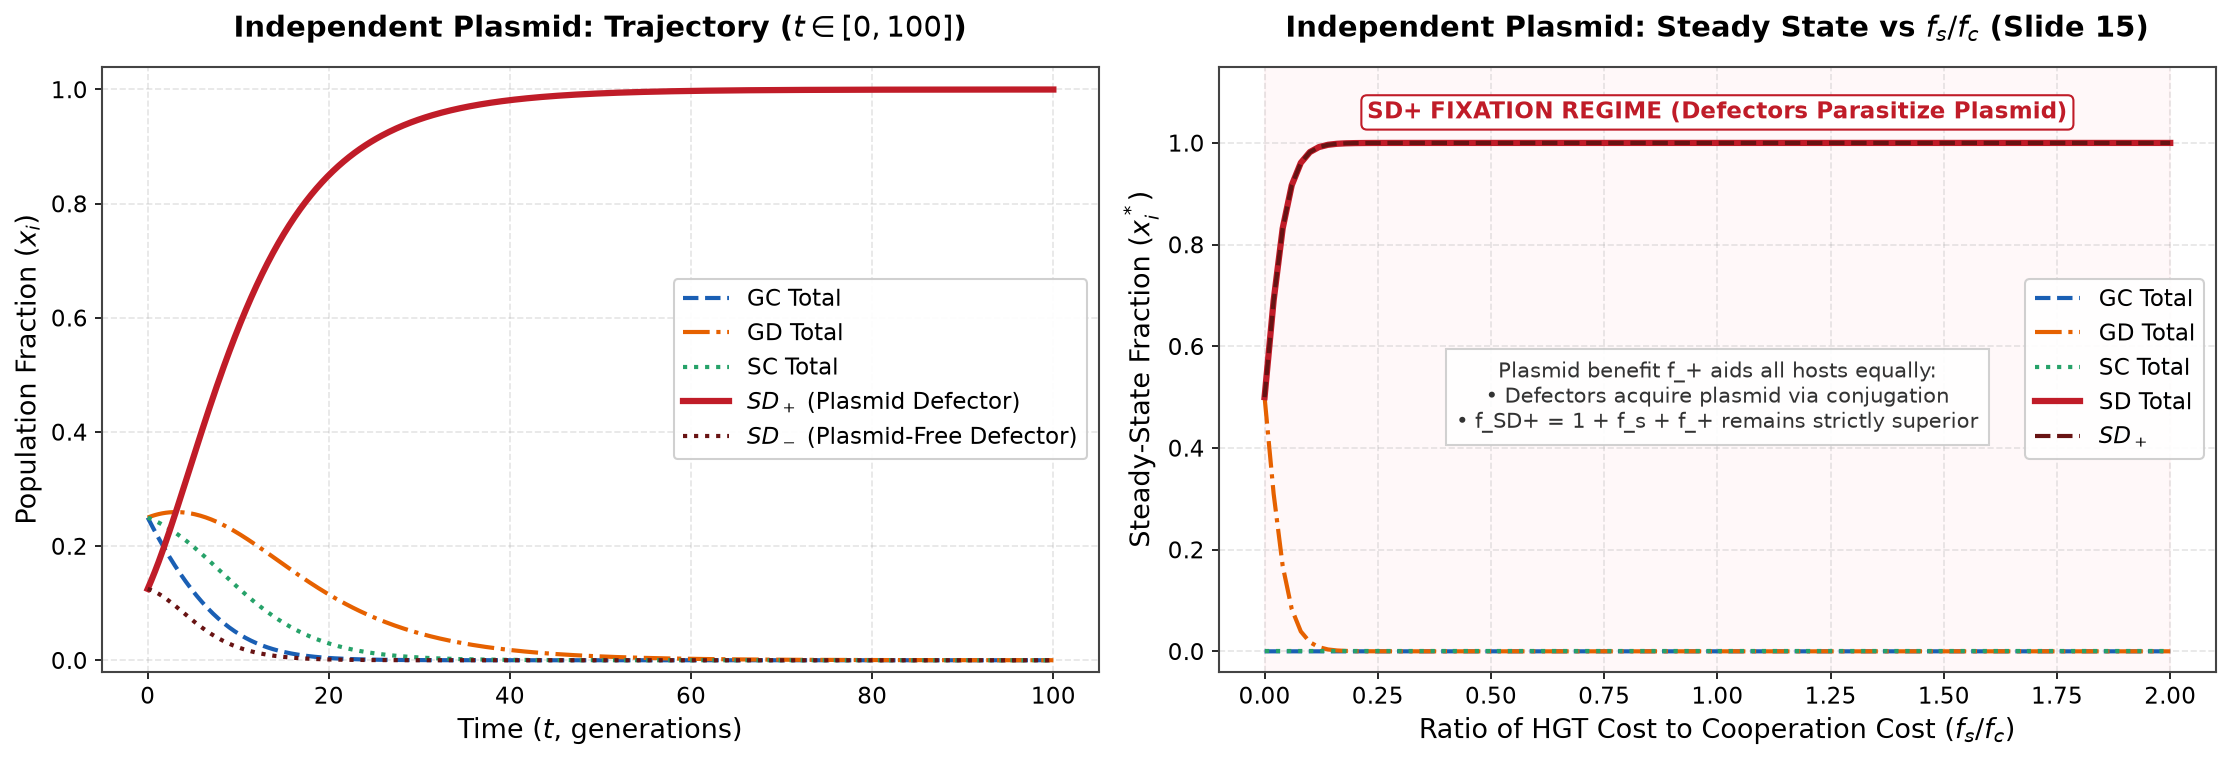

In [3]:
def independent_plasmid_ode(t, y, alpha, fc, fs, fplus):
    GC_p, GC_m, GD_p, GD_m, SC_p, SC_m, SD_p, SD_m = y
    
    f_GC_p = 1.0 - fc + fplus
    f_GC_m = 1.0 - fc
    f_GD_p = 1.0 + fplus
    f_GD_m = 1.0
    f_SC_p = 1.0 + fs - fc + fplus
    f_SC_m = 1.0 + fs - fc
    f_SD_p = 1.0 + fs + fplus
    f_SD_m = 1.0 + fs
    
    f_bar = (1.0 - fc * (GC_p + GC_m + SC_p + SC_m)
             + fs * (SC_p + SC_m + SD_p + SD_m)
             + fplus * (GC_p + GD_p + SC_p + SD_p))
    
    dGC_p = (f_GC_p - f_bar) * GC_p + alpha * (GC_p*GC_m + GC_p*GD_p + GC_p*GD_m + 2.0*GC_m*GD_p)
    dGC_m = (f_GC_m - f_bar) * GC_m + alpha * (GC_m*GD_m - GC_p*GC_m - GC_m*GD_p)
    dGD_p = (f_GD_p - f_bar) * GD_p + alpha * (GD_p*GD_m - GC_p*GD_p - GC_m*GD_p)
    dGD_m = (f_GD_m - f_bar) * GD_m + alpha * (-GC_p*GD_m - GC_m*GD_m - GD_p*GD_m)
    dSC_p = (f_SC_p - f_bar) * SC_p + alpha * (GC_p*SC_m + GC_p*SD_p + GC_p*SD_m + GC_m*SD_p + GD_p*SC_m)
    dSC_m = (f_SC_m - f_bar) * SC_m + alpha * (GC_m*SD_m - GC_p*SC_m - GD_p*SC_m)
    dSD_p = (f_SD_p - f_bar) * SD_p + alpha * (GD_p*SD_m - GC_p*SD_p - GC_m*SD_p)
    dSD_m = (f_SD_m - f_bar) * SD_m + alpha * (-GD_p*SD_m - GC_p*SD_m - GC_m*SD_m)
    
    return [dGC_p, dGC_m, dGD_p, dGD_m, dSC_p, dSC_m, dSD_p, dSD_m]

# 1. Simulate time series
y0_indep = [1/8.0] * 8
fplus = 0.3
sol_indep = spi.solve_ivp(independent_plasmid_ode, t_span, y0_indep, args=(alpha, fc, fs, fplus), t_eval=t_eval, method='RK45')

# 2. Parameter sweep vs fs / fc (Slide 15)
indep_sweep = []
for r in ratios:
    sol = spi.solve_ivp(independent_plasmid_ode, (0, 200), y0_indep, args=(alpha, fc, r * fc, fplus), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    indep_sweep.append(final / np.sum(final))
indep_sweep = np.array(indep_sweep)

# Clean, non-overlapping figure layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))

# Subplot 1: Trajectory
ax1.plot(sol_indep.t, sol_indep.y[0] + sol_indep.y[1], label="GC Total", color=COLOR_GC, linestyle="--", linewidth=2.0)
ax1.plot(sol_indep.t, sol_indep.y[2] + sol_indep.y[3], label="GD Total", color=COLOR_GD, linestyle="-.", linewidth=2.0)
ax1.plot(sol_indep.t, sol_indep.y[4] + sol_indep.y[5], label="SC Total", color=COLOR_SC, linestyle=":", linewidth=2.0)
ax1.plot(sol_indep.t, sol_indep.y[6], label="$SD_+$ (Plasmid Defector)", color=COLOR_SD, linestyle="-", linewidth=3.0)
ax1.plot(sol_indep.t, sol_indep.y[7], label="$SD_-$ (Plasmid-Free Defector)", color=COLOR_SD_PLUS, linestyle=":", linewidth=2.0)
ax1.set_title("Independent Plasmid: Trajectory ($t \\in [0, 100]$)", pad=14)
ax1.set_xlabel("Time ($t$, generations)")
ax1.set_ylabel("Population Fraction ($x_i$)")
ax1.set_ylim(-0.02, 1.04)
ax1.legend(loc="center right", framealpha=0.92)

# Subplot 2: Bifurcation (Slide 15)
total_sd = indep_sweep[:, 6] + indep_sweep[:, 7]
total_gc = indep_sweep[:, 0] + indep_sweep[:, 1]
total_gd = indep_sweep[:, 2] + indep_sweep[:, 3]
total_sc = indep_sweep[:, 4] + indep_sweep[:, 5]

ax2.plot(ratios, total_gc, label="GC Total", color=COLOR_GC, linestyle="--", linewidth=2.0)
ax2.plot(ratios, total_gd, label="GD Total", color=COLOR_GD, linestyle="-.", linewidth=2.0)
ax2.plot(ratios, total_sc, label="SC Total", color=COLOR_SC, linestyle=":", linewidth=2.0)
ax2.plot(ratios, total_sd, label="SD Total", color=COLOR_SD, linestyle="-", linewidth=3.0)
ax2.plot(ratios, indep_sweep[:, 6], label=r"$SD_+$", color=COLOR_SD_PLUS, linestyle="--", linewidth=2.0)
ax2.axvspan(0.0, 2.0, color=SHADE_SD, alpha=0.35)
ax2.set_title("Independent Plasmid: Steady State vs $f_s / f_c$ (Slide 15)", pad=14)
ax2.set_xlabel(r"Ratio of HGT Cost to Cooperation Cost ($f_s / f_c$)")
ax2.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax2.set_ylim(-0.04, 1.15)
ax2.text(1.0, 1.06, "SD+ FIXATION REGIME (Defectors Parasitize Plasmid)",
         ha="center", va="center", color=COLOR_SD, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=COLOR_SD, linewidth=1.0))
ax2.text(1.0, 0.50,
         "Plasmid benefit f_+ aids all hosts equally:\n"
         "• Defectors acquire plasmid via conjugation\n"
         "• f_SD+ = 1 + f_s + f_+ remains strictly superior",
         ha="center", va="center", fontsize=10, color="#333333",
         bbox=dict(boxstyle="square,pad=0.5", facecolor="#ffffff", edgecolor="#cccccc", alpha=0.9))
ax2.legend(loc="center right", framealpha=0.92)

plt.tight_layout()
plt.show()


### Inferences from Independent Beneficial Plasmid Model
- **Universal Benefit Flaw:** Because $f_+$ provides equal fitness value to all hosts regardless of cooperation or HGT, the relative fitness differences between types are completely unchanged:
  $$f_{SD_+} - f_{SC_+} = f_c, \quad f_{SD_+} - f_{GD_+} = f_s$$
- **Plasmid Hijacking:** Defectors readily acquire the beneficial plasmid via conjugation ($SD_- + GD_+ \to SD_+ + GD_+$), achieving maximal fitness $f_{SD_+} = 1 + f_s + f_+$.
- **Conclusion:** An independent beneficial plasmid acts as an evolutionary parasite of the social system: it invades the population without rescuing either cooperation or HGT.


---
## 3. Model 3: Dependent Beneficial Plasmid Model (Slides 16–20)

### 3.1 Six Population Types & Conditional Fitness
To link plasmid propagation to sociality, we assume that the plasmid confers a fitness benefit **only when expressed in cooperative hosts** (e.g., public goods machinery enhances plasmid retention, or plasmid carries an enzyme that complements cooperative metabolism).
Defectors do not maintain or benefit from the plasmid, reducing the state space to 6 types:
$$x = [GC_+, GC_-, GD, SC_+, SC_-, SD]^\top$$

### 3.2 Fitness & Mean Fitness
$$\begin{aligned}
f_{GC_+} &= 1 - f_c + f_+ \\
f_{GC_-} &= 1 - f_c \\
f_{GD}   &= 1 \\
f_{SC_+} &= 1 + f_s - f_c + f_+ \\
f_{SC_-} &= 1 + f_s - f_c \\
f_{SD}   &= 1 + f_s
\end{aligned}$$

Mean fitness:
$$\bar{f} = 1 - f_c(GC_+ + GC_- + SC_+ + SC_-) + f_s(SC_+ + SC_- + SD) + f_+(GC_+ + SC_+)$$

### 3.3 Critical Bifurcation Threshold
Notice the fitness competition between the fittest cooperator ($SC_+$) and the fittest defector ($SD$):
$$f_{SC_+} - f_{SD} = (1 + f_s - f_c + f_+) - (1 + f_s) = f_+ - f_c$$
- **Subcritical Regime ($f_+ < f_c \iff f_+ / f_c < 1$):** Defectors have higher fitness; $SD$ dominates.
- **Supercritical Regime ($f_+ > f_c \iff f_+ / f_c > 1$):** Cooperators with plasmid ($SC_+$) outcompete defectors!


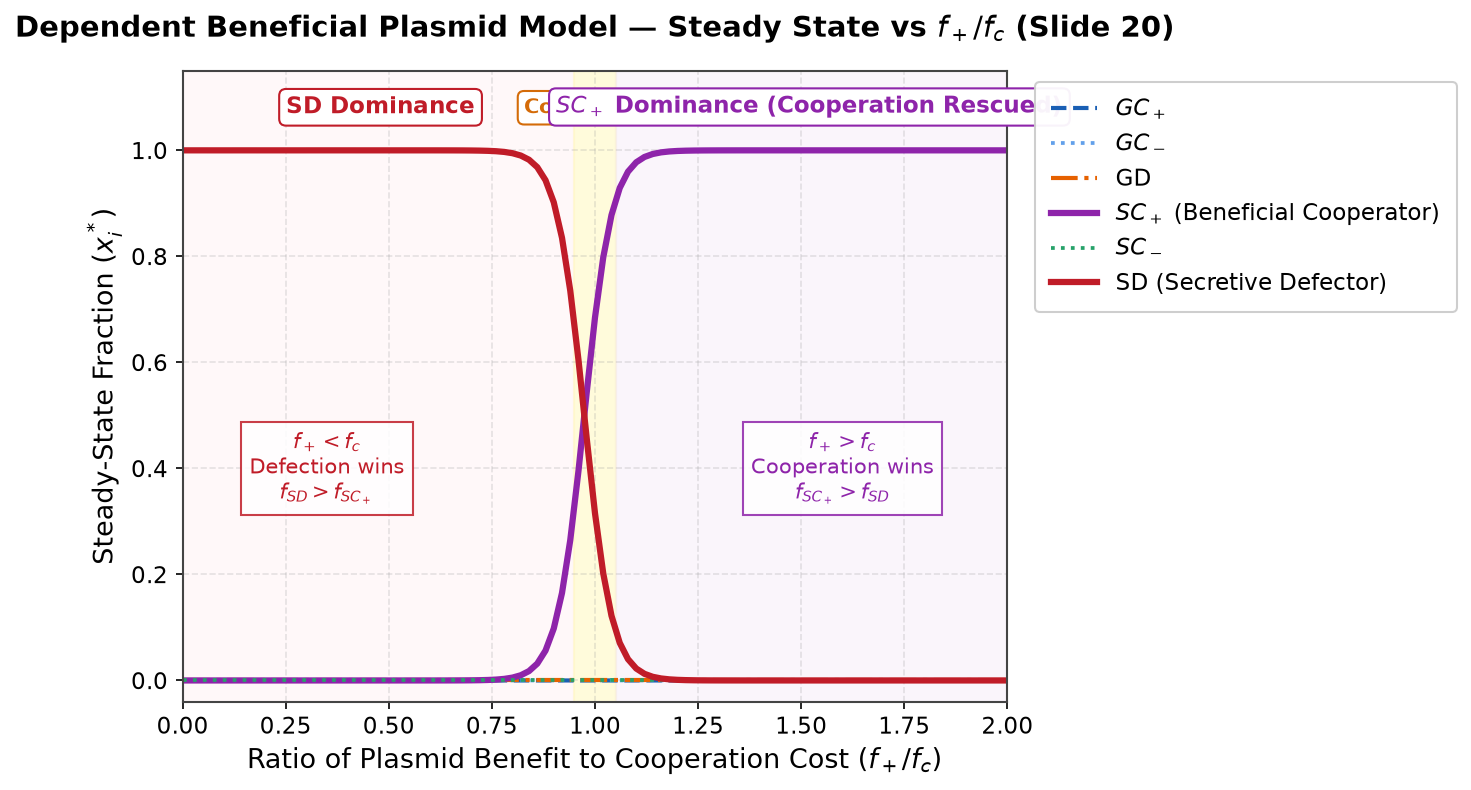

In [4]:
def dependent_plasmid_ode(t, y, alpha, fc, fs, fplus):
    GC_p, GC_m, GD, SC_p, SC_m, SD = y
    
    f_GC_p = 1.0 - fc + fplus
    f_GC_m = 1.0 - fc
    f_GD   = 1.0
    f_SC_p = 1.0 + fs - fc + fplus
    f_SC_m = 1.0 + fs - fc
    f_SD   = 1.0 + fs
    
    f_bar = (1.0 - fc * (GC_p + GC_m + SC_p + SC_m)
             + fs * (SC_p + SC_m + SD)
             + fplus * (GC_p + SC_p))
    
    dGC_p = (f_GC_p - f_bar) * GC_p + alpha * (GC_p * GD + GC_p * GC_m)
    dGC_m = (f_GC_m - f_bar) * GC_m + alpha * (GC_m * GD + GC_m * SD - GC_p * GC_m)
    dGD   = (f_GD   - f_bar) * GD   - alpha * (GC_p * GD + GC_m * GD)
    dSC_p = (f_SC_p - f_bar) * SC_p + alpha * (GC_p * SD + SC_m * GC_p)
    dSC_m = (f_SC_m - f_bar) * SC_m - alpha * (SC_m * GC_p)
    dSD   = (f_SD   - f_bar) * SD   - alpha * (GC_p * SD + GC_m * SD)
    
    return [dGC_p, dGC_m, dGD, dSC_p, dSC_m, dSD]

# Parameter sweep vs f+ / fc (Slide 20)
ratios_fplus = np.linspace(0.0, 2.0, 101)
y0_dep = [1/6.0] * 6
dep_sweep = []
for r in ratios_fplus:
    sol = spi.solve_ivp(dependent_plasmid_ode, (0, 150), y0_dep, args=(alpha, fc, fs, r * fc), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    dep_sweep.append(final / np.sum(final))
dep_sweep = np.array(dep_sweep)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
ax.plot(ratios_fplus, dep_sweep[:, 0], label="$GC_+$", color=COLOR_GC, linestyle="--", linewidth=2.0)
ax.plot(ratios_fplus, dep_sweep[:, 1], label="$GC_-$", color=COLOR_GC_MINUS, linestyle=":", linewidth=1.8)
ax.plot(ratios_fplus, dep_sweep[:, 2], label="GD", color=COLOR_GD, linestyle="-.", linewidth=2.0)
ax.plot(ratios_fplus, dep_sweep[:, 3], label="$SC_+$ (Beneficial Cooperator)", color=COLOR_SC_PLUS, linewidth=3.0)
ax.plot(ratios_fplus, dep_sweep[:, 4], label="$SC_-$", color=COLOR_SC, linestyle=":", linewidth=1.8)
ax.plot(ratios_fplus, dep_sweep[:, 5], label="SD (Secretive Defector)", color=COLOR_SD, linewidth=3.0)

# Shaded background zones matching Slide 20
ax.axvspan(0.0, 0.95, color=SHADE_SD, alpha=0.35)
ax.axvspan(0.95, 1.05, color=SHADE_COEX, alpha=0.6)
ax.axvspan(1.05, 2.0, color=SHADE_SC_PLUS, alpha=0.35)

ax.set_title("Dependent Beneficial Plasmid Model — Steady State vs $f_+ / f_c$ (Slide 20)", pad=16)
ax.set_xlabel(r"Ratio of Plasmid Benefit to Cooperation Cost ($f_+ / f_c$)")
ax.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax.set_xlim(0.0, 2.0)
ax.set_ylim(-0.04, 1.15)

# Header banner strip
ax.text(0.48, 1.07, "SD Dominance", fontsize=11, fontweight="bold", color=COLOR_SD, ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=COLOR_SD, linewidth=1.0))
ax.text(1.0, 1.07, "Coexistence", fontsize=10, fontweight="bold", color="#d46b08", ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#d46b08", linewidth=1.0))
ax.text(1.52, 1.07, r"$SC_+$ Dominance (Cooperation Rescued)", fontsize=11, fontweight="bold", color=COLOR_SC_PLUS, ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=COLOR_SC_PLUS, linewidth=1.0))

# Clear annotations in guaranteed empty lower-left and lower-right corners
ax.text(0.35, 0.40,
        r"$f_+ < f_c$" "\n"
        "Defection wins\n"
        r"$f_{SD} > f_{SC_+}$",
        ha="center", va="center", fontsize=10, color=COLOR_SD,
        bbox=dict(boxstyle="square,pad=0.4", facecolor="#ffffff", edgecolor=COLOR_SD, alpha=0.85))

ax.text(1.60, 0.40,
        r"$f_+ > f_c$" "\n"
        "Cooperation wins\n"
        r"$f_{SC_+} > f_{SD}$",
        ha="center", va="center", fontsize=10, color=COLOR_SC_PLUS,
        bbox=dict(boxstyle="square,pad=0.4", facecolor="#ffffff", edgecolor=COLOR_SC_PLUS, alpha=0.85))

ax.legend(bbox_to_anchor=(1.02, 1.0), loc="upper left", framealpha=0.95, borderpad=0.7, edgecolor="#cccccc")

plt.tight_layout()
plt.show()


### Inferences from Dependent Beneficial Plasmid Model
- **Cooperation Rescued:** When plasmid benefit depends on cooperation and exceeds cooperation cost ($f_+ > f_c$), cooperative bacteria ($SC_+$) outcompete defectors and fixate in the population!
- **HGT Remains Extinct:** Even though cooperation is saved, generous types ($GC$) are still eliminated because $SC_+$ avoids the cost of conjugation ($f_s$). $GC_+$ pays $f_s$ while $SC_+$ avoids it, so $SC_+$ outgrows $GC_+$.
- **Evolutionary Dilemma:** A dependent plasmid rescues cooperation, but fails to explain the evolution and maintenance of horizontal gene transfer.


---
## 4. Model 4: Plasmid–Chromosome Synergy Model (Slides 21–24)

### 4.1 Positive Epistasis Between Chromosome & Plasmid
In nature, chromosomal genes encoding HGT machinery often exhibit **positive epistasis (synergy)** with plasmid genes (San Millan et al., 2014, *ISME Journal*). For instance, chromosomal relaxases and plasmid partition systems co-optimize cellular metabolism.

In this model:
- The synergistic gain $f_{pc}$ is conferred **specifically to Generous Cooperators ($GC$)**, which carry both chromosomal HGT genes and the cooperative plasmid.
- Population reverts to four core strategies: $x = [GC, GD, SC, SD]^\top$.

### 4.2 Fitness & Mean Fitness
$$\begin{aligned}
f_{GC} &= 1 - f_c + f_{pc} \\
f_{GD} &= 1 \\
f_{SC} &= 1 + f_s - f_c \\
f_{SD} &= 1 + f_s
\end{aligned}$$

Mean fitness:
$$\bar{f} = 1 - f_c(GC + SC) + f_s(SC + SD) + f_{pc}GC$$

### 4.3 Replicator Dynamics & Inherent Threshold
$$\begin{aligned}
\dot{GC} &= (f_{GC} - \bar{f})GC + \alpha \cdot GC \cdot GD \\
\dot{GD} &= (f_{GD} - \bar{f})GD - \alpha \cdot GC \cdot GD \\
\dot{SC} &= (f_{SC} - \bar{f})SC + \alpha \cdot GC \cdot SD \\
\dot{SD} &= (f_{SD} - \bar{f})SD - \alpha \cdot GC \cdot SD
\end{aligned}$$

Comparing $GC$ directly with $SD$:
$$f_{GC} - f_{SD} = (1 - f_c + f_{pc}) - (1 + f_s) = f_{pc} - (f_s + f_c)$$

The critical ratio is:
$$\Gamma = \frac{f_{pc}}{f_s + f_c}$$
- **Low Synergy ($\Gamma < 0.7$):** Defectors dominate ($SD = 1.0$).
- **Intermediate Synergy ($0.7 \le \Gamma \le 1.1$):** Coexistence regime! Both $GC$ and $SD$ persist simultaneously.
- **High Synergy ($\Gamma > 1.1$):** Generous cooperators dominate ($GC = 1.0$). **Both HGT and Cooperation win!**


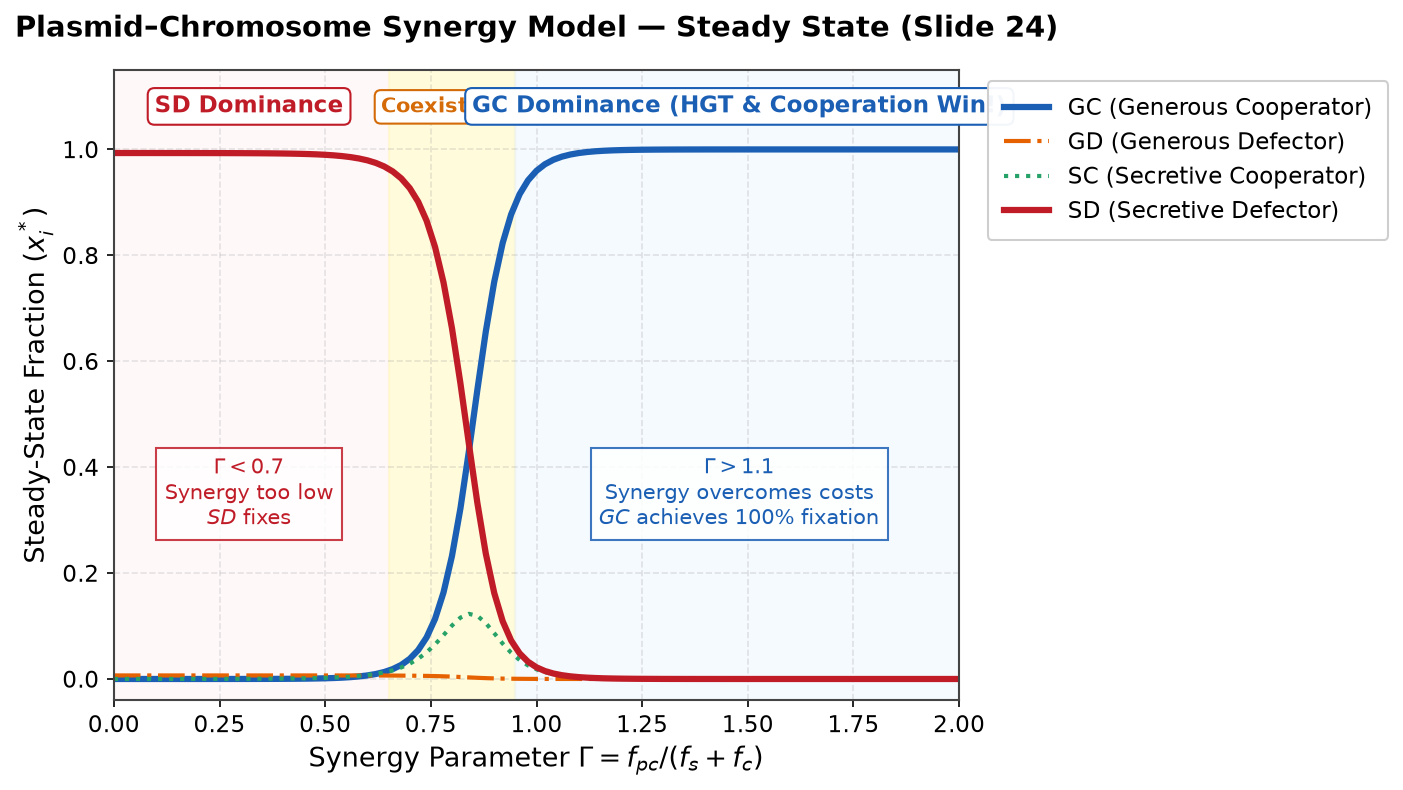

In [5]:
def synergy_model_ode(t, y, alpha, fc, fs, fpc):
    GC, GD, SC, SD = y
    f_GC = 1.0 - fc + fpc
    f_GD = 1.0
    f_SC = 1.0 + fs - fc
    f_SD = 1.0 + fs
    
    f_bar = 1.0 - fc * (GC + SC) + fs * (SC + SD) + fpc * GC
    
    dGC = (f_GC - f_bar) * GC + alpha * GC * GD
    dGD = (f_GD - f_bar) * GD - alpha * GC * GD
    dSC = (f_SC - f_bar) * SC + alpha * GC * SD
    dSD = (f_SD - f_bar) * SD - alpha * GC * SD
    return [dGC, dGD, dSC, dSD]

# Parameter sweep vs f_pc / (f_s + f_c) (Slide 24)
ratios_fpc = np.linspace(0.0, 2.0, 101)
y0_synergy = [0.25, 0.25, 0.25, 0.25]
synergy_sweep = []
# Finite horizon T=50 captures the observable coexistence regime and critical slowing down (Slide 24)
for r in ratios_fpc:
    fpc = r * (fs + fc)
    sol = spi.solve_ivp(synergy_model_ode, (0, 50), y0_synergy, args=(alpha, fc, fs, fpc), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    synergy_sweep.append(final / np.sum(final))
synergy_sweep = np.array(synergy_sweep)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
ax.plot(ratios_fpc, synergy_sweep[:, 0], label="GC (Generous Cooperator)", color=COLOR_GC, linewidth=3.0)
ax.plot(ratios_fpc, synergy_sweep[:, 1], label="GD (Generous Defector)", color=COLOR_GD, linestyle="-.", linewidth=2.0)
ax.plot(ratios_fpc, synergy_sweep[:, 2], label="SC (Secretive Cooperator)", color=COLOR_SC, linestyle=":", linewidth=2.0)
ax.plot(ratios_fpc, synergy_sweep[:, 3], label="SD (Secretive Defector)", color=COLOR_SD, linewidth=3.0)

# Shaded background regimes matching Slide 24
ax.axvspan(0.0, 0.65, color=SHADE_SD, alpha=0.35)
ax.axvspan(0.65, 0.95, color=SHADE_COEX, alpha=0.6)
ax.axvspan(0.95, 2.0, color=SHADE_GC, alpha=0.35)

ax.set_title(r"Plasmid–Chromosome Synergy Model — Steady State (Slide 24)", pad=16)
ax.set_xlabel(r"Synergy Parameter $\Gamma = f_{pc} / (f_s + f_c)$")
ax.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax.set_xlim(0.0, 2.0)
ax.set_ylim(-0.04, 1.15)

# Dedicated header banner strip for regimes
ax.text(0.32, 1.07, "SD Dominance", fontsize=11, fontweight="bold", color=COLOR_SD, ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=COLOR_SD, linewidth=1.0))
ax.text(0.80, 1.07, "Coexistence", fontsize=10, fontweight="bold", color="#d46b08", ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#d46b08", linewidth=1.0))
ax.text(1.48, 1.07, "GC Dominance (HGT & Cooperation Win!)", fontsize=11, fontweight="bold", color=COLOR_GC, ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=COLOR_GC, linewidth=1.0))

# Clear annotations in guaranteed empty lower-left and lower-right corners
ax.text(0.32, 0.35,
        r"$\Gamma < 0.7$" "\n"
        "Synergy too low\n"
        r"$SD$ fixes",
        ha="center", va="center", fontsize=10, color=COLOR_SD,
        bbox=dict(boxstyle="square,pad=0.4", facecolor="#ffffff", edgecolor=COLOR_SD, alpha=0.85))

ax.text(1.48, 0.35,
        r"$\Gamma > 1.1$" "\n"
        "Synergy overcomes costs\n"
        r"$GC$ achieves 100% fixation",
        ha="center", va="center", fontsize=10, color=COLOR_GC,
        bbox=dict(boxstyle="square,pad=0.4", facecolor="#ffffff", edgecolor=COLOR_GC, alpha=0.85))

ax.legend(bbox_to_anchor=(1.02, 1.0), loc="upper left", framealpha=0.95, borderpad=0.7, edgecolor="#cccccc")

plt.tight_layout()
plt.show()


### Inferences from Plasmid-Chromosome Synergy Model
- **Synergy Bridges the Fitness Gap:** By providing $f_{pc}$ directly to cells carrying both HGT machinery and the cooperative plasmid, $GC$ overcomes both costs simultaneously.
- **Conjugation Accelerates the Takeover:** Once $GC$ gains a fitness advantage, its conjugation actively converts defectors ($GD \to GC$), creating an epidemic-like positive feedback loop that drives $GC$ to 100% fixation.
- **Resolution of the Paradox:** Plasmid-chromosome synergy provides a robust, biologically grounded mechanism explaining how costly horizontal gene transfer and costly cooperation can co-evolve in bacterial populations!


---
## 5. Master Comparative Synthesis (All 4 Models)

The master figure below compiles the steady-state outcomes of all four evolutionary models:


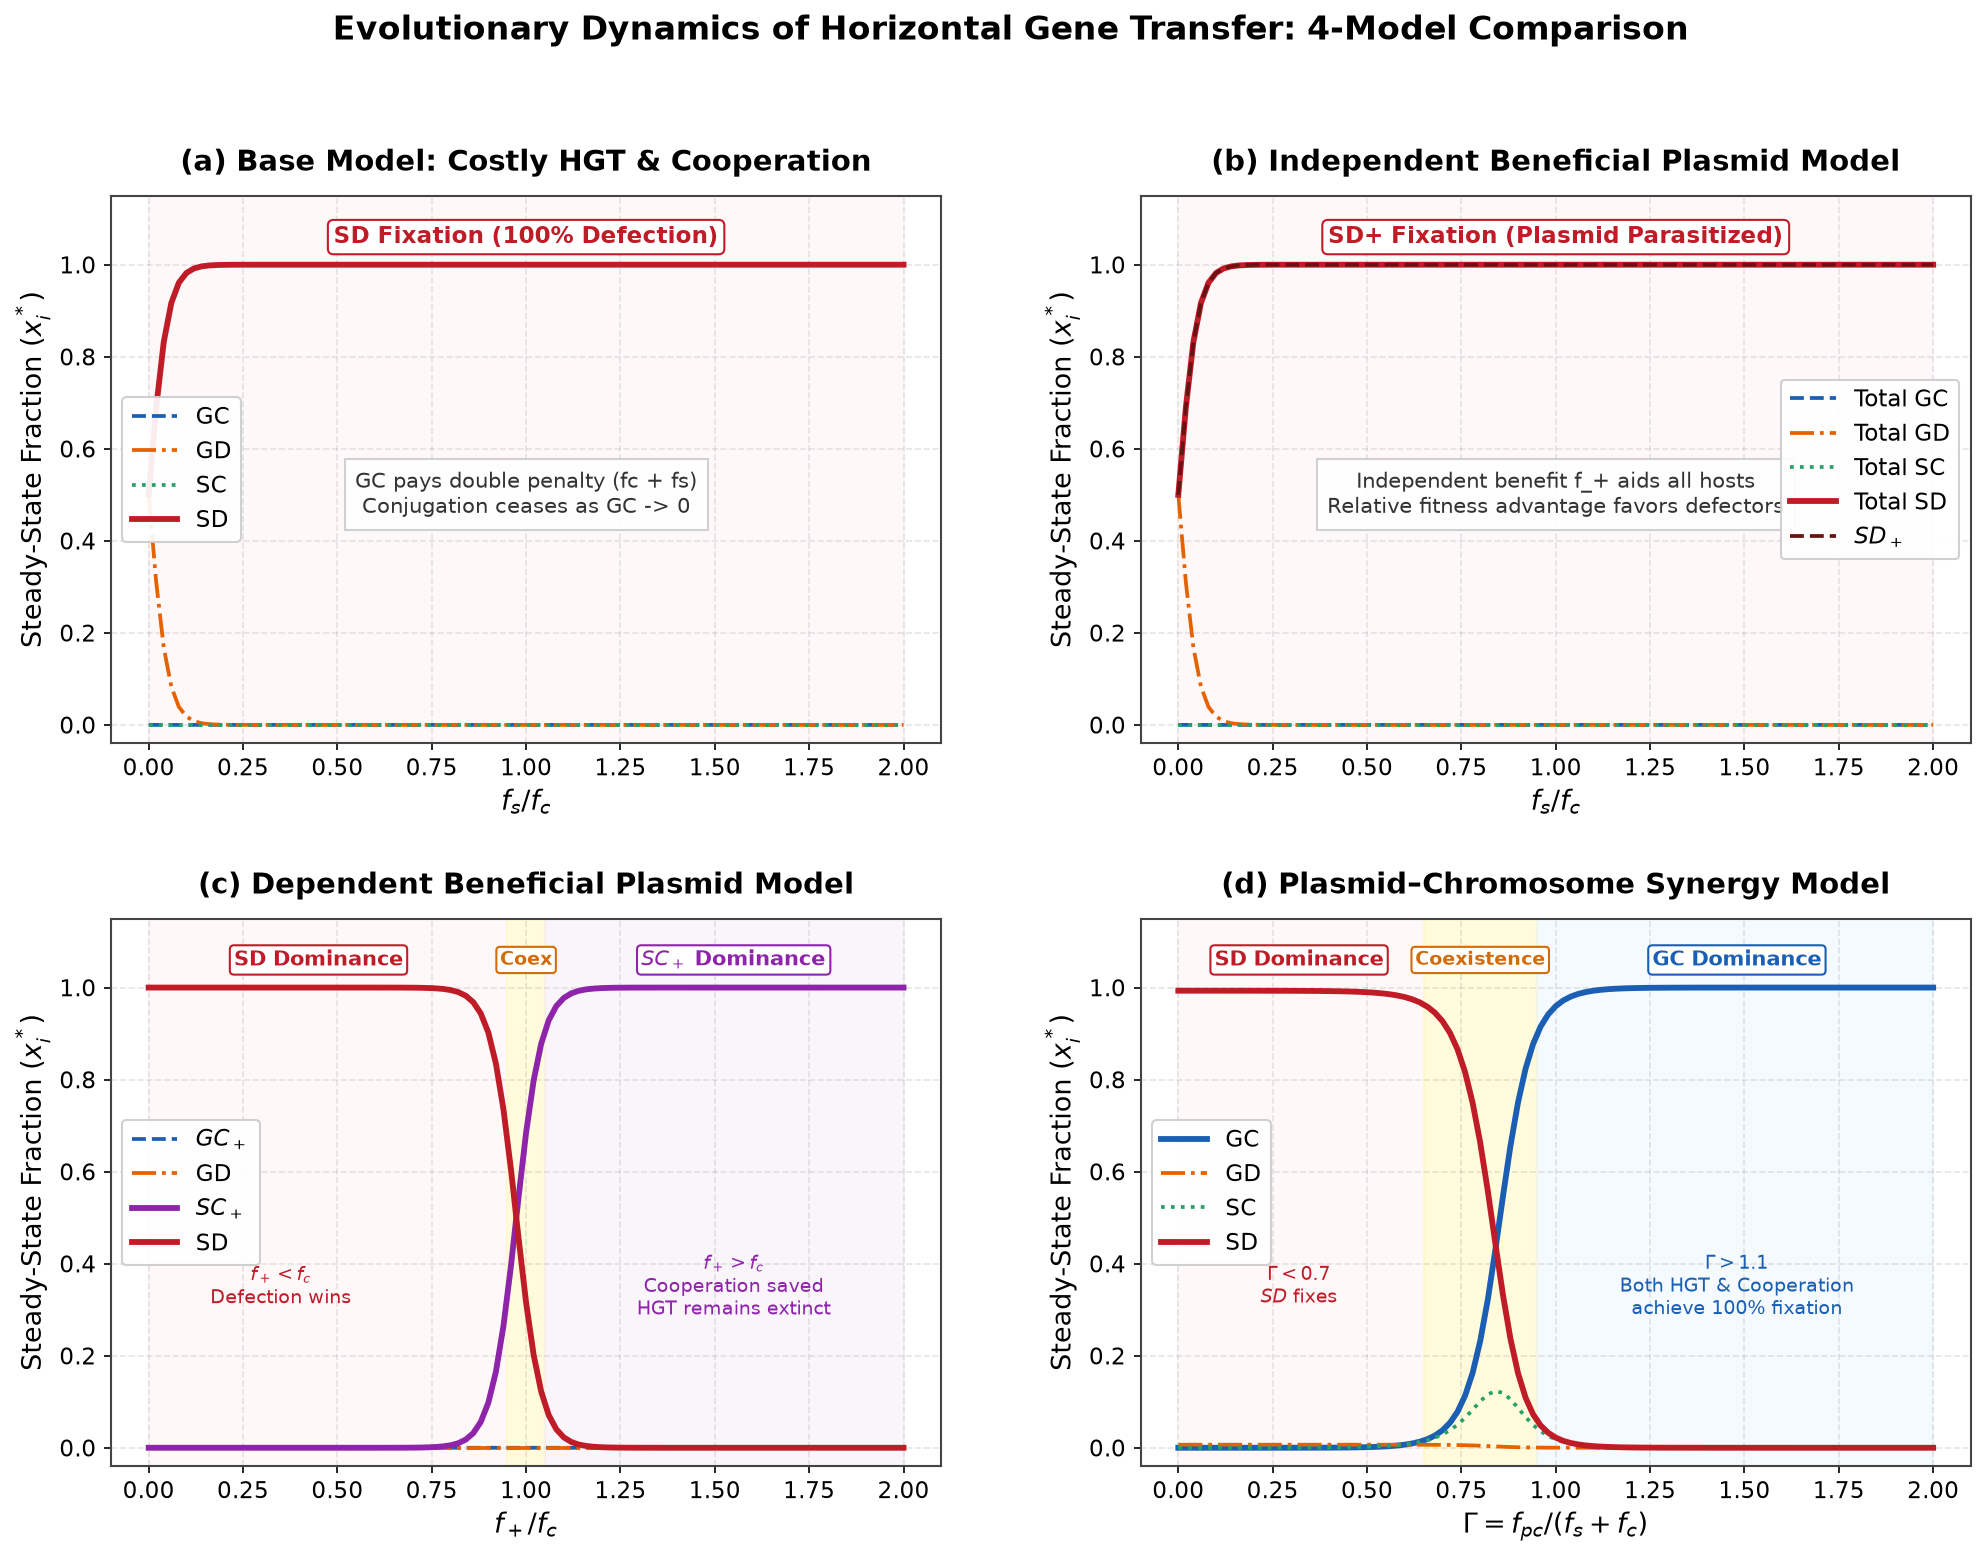

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel (a): Base Model
ax = axes[0, 0]
ax.plot(ratios, base_sweep[:, 0], label="GC", color=COLOR_GC, linestyle="--", linewidth=1.8)
ax.plot(ratios, base_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.", linewidth=1.8)
ax.plot(ratios, base_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":", linewidth=1.8)
ax.plot(ratios, base_sweep[:, 3], label="SD", color=COLOR_SD, linewidth=2.8)
ax.axvspan(0.0, 2.0, color=SHADE_SD, alpha=0.35)
ax.set_title("(a) Base Model: Costly HGT & Cooperation", pad=12)
ax.set_xlabel(r"$f_s / f_c$")
ax.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax.set_ylim(-0.04, 1.15)
ax.text(1.0, 1.06, "SD Fixation (100% Defection)", ha="center", va="center", color=COLOR_SD, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=COLOR_SD, linewidth=1.0))
ax.text(1.0, 0.50, "GC pays double penalty (fc + fs)\nConjugation ceases as GC -> 0",
        ha="center", va="center", fontsize=10, color="#333333",
        bbox=dict(boxstyle="square,pad=0.5", facecolor="#ffffff", edgecolor="#cccccc", alpha=0.9))
ax.legend(loc="center left", framealpha=0.92)

# Panel (b): Independent Beneficial Plasmid
ax = axes[0, 1]
ax.plot(ratios, total_gc, label="Total GC", color=COLOR_GC, linestyle="--", linewidth=1.8)
ax.plot(ratios, total_gd, label="Total GD", color=COLOR_GD, linestyle="-.", linewidth=1.8)
ax.plot(ratios, total_sc, label="Total SC", color=COLOR_SC, linestyle=":", linewidth=1.8)
ax.plot(ratios, total_sd, label="Total SD", color=COLOR_SD, linewidth=2.8)
ax.plot(ratios, indep_sweep[:, 6], label=r"$SD_+$", color=COLOR_SD_PLUS, linestyle="--", linewidth=1.8)
ax.axvspan(0.0, 2.0, color=SHADE_SD, alpha=0.35)
ax.set_title("(b) Independent Beneficial Plasmid Model", pad=12)
ax.set_xlabel(r"$f_s / f_c$")
ax.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax.set_ylim(-0.04, 1.15)
ax.text(1.0, 1.06, "SD+ Fixation (Plasmid Parasitized)", ha="center", va="center", color=COLOR_SD, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=COLOR_SD, linewidth=1.0))
ax.text(1.0, 0.50, "Independent benefit f_+ aids all hosts\nRelative fitness advantage favors defectors",
        ha="center", va="center", fontsize=10, color="#333333",
        bbox=dict(boxstyle="square,pad=0.5", facecolor="#ffffff", edgecolor="#cccccc", alpha=0.9))
ax.legend(loc="center right", framealpha=0.92)

# Panel (c): Dependent Beneficial Plasmid
ax = axes[1, 0]
ax.plot(ratios_fplus, dep_sweep[:, 0], label="$GC_+$", color=COLOR_GC, linestyle="--", linewidth=1.8)
ax.plot(ratios_fplus, dep_sweep[:, 2], label="GD", color=COLOR_GD, linestyle="-.", linewidth=1.8)
ax.plot(ratios_fplus, dep_sweep[:, 3], label="$SC_+$", color=COLOR_SC_PLUS, linewidth=2.8)
ax.plot(ratios_fplus, dep_sweep[:, 5], label="SD", color=COLOR_SD, linewidth=2.8)
ax.axvspan(0.0, 0.95, color=SHADE_SD, alpha=0.35)
ax.axvspan(0.95, 1.05, color=SHADE_COEX, alpha=0.6)
ax.axvspan(1.05, 2.0, color=SHADE_SC_PLUS, alpha=0.35)
ax.set_title("(c) Dependent Beneficial Plasmid Model", pad=12)
ax.set_xlabel(r"$f_+ / f_c$")
ax.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax.set_ylim(-0.04, 1.15)
ax.text(0.45, 1.06, "SD Dominance", ha="center", va="center", color=COLOR_SD, fontweight="bold", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=COLOR_SD))
ax.text(1.0, 1.06, "Coex", ha="center", va="center", color="#d46b08", fontweight="bold", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#d46b08"))
ax.text(1.55, 1.06, "$SC_+$ Dominance", ha="center", va="center", color=COLOR_SC_PLUS, fontweight="bold", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=COLOR_SC_PLUS))
ax.text(0.35, 0.35, r"$f_+ < f_c$" "\nDefection wins", ha="center", va="center", fontsize=9, color=COLOR_SD)
ax.text(1.55, 0.35, r"$f_+ > f_c$" "\nCooperation saved\nHGT remains extinct", ha="center", va="center", fontsize=9, color=COLOR_SC_PLUS)
ax.legend(loc="center left", framealpha=0.92)

# Panel (d): Plasmid-Chromosome Synergy
ax = axes[1, 1]
ax.plot(ratios_fpc, synergy_sweep[:, 0], label="GC", color=COLOR_GC, linewidth=2.8)
ax.plot(ratios_fpc, synergy_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.", linewidth=1.8)
ax.plot(ratios_fpc, synergy_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":", linewidth=1.8)
ax.plot(ratios_fpc, synergy_sweep[:, 3], label="SD", color=COLOR_SD, linewidth=2.8)
ax.axvspan(0.0, 0.65, color=SHADE_SD, alpha=0.35)
ax.axvspan(0.65, 0.95, color=SHADE_COEX, alpha=0.6)
ax.axvspan(0.95, 2.0, color=SHADE_GC, alpha=0.35)
ax.set_title("(d) Plasmid–Chromosome Synergy Model", pad=12)
ax.set_xlabel(r"$\Gamma = f_{pc} / (f_s + f_c)$")
ax.set_ylabel("Steady-State Fraction ($x_i^*$)")
ax.set_ylim(-0.04, 1.15)
ax.text(0.32, 1.06, "SD Dominance", ha="center", va="center", color=COLOR_SD, fontweight="bold", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=COLOR_SD))
ax.text(0.80, 1.06, "Coexistence", ha="center", va="center", color="#d46b08", fontweight="bold", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#d46b08"))
ax.text(1.48, 1.06, "GC Dominance", ha="center", va="center", color=COLOR_GC, fontweight="bold", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=COLOR_GC))
ax.text(0.32, 0.35, r"$\Gamma < 0.7$" "\n$SD$ fixes", ha="center", va="center", fontsize=9, color=COLOR_SD)
ax.text(1.48, 0.35, r"$\Gamma > 1.1$" "\nBoth HGT & Cooperation\nachieve 100% fixation", ha="center", va="center", fontsize=9, color=COLOR_GC)
ax.legend(loc="center left", framealpha=0.92)

plt.suptitle("Evolutionary Dynamics of Horizontal Gene Transfer: 4-Model Comparison", fontsize=16, y=0.99)
plt.subplots_adjust(hspace=0.32, wspace=0.24)
plt.show()


---
## 6. Future Directions & Research Extensions

1. **Spatial Structure & Viscous Populations:**
   - Real microbial communities inhabit structured biofilms where diffusion is localized.
   - *Extension:* Implement reaction-diffusion PDEs or 2D cellular automata (agent-based lattices) to examine how spatial clustering protects cooperators from cheater exploitation.

2. **Demographic Stochasticity & Genetic Drift:**
   - Deterministic ODEs assume infinite population size ($N \to \infty$). In small colonies or transmission bottlenecks, demographic noise can flip stable states.
   - *Extension:* Formulate continuous-time Markov jump processes (Gillespie algorithm) and calculate fixation probabilities as a function of effective population size $N_e$.

3. **Chemostat Dilution & Resource Dynamics:**
   - Incorporate explicit substrate ($S$) and public goods ($P$) equations:
     $$\frac{dS}{dt} = D(S_0 - S) - \sum_i \mu_i(S) x_i$$
   - Model conjugation as cell-contact dependent on total biomass density rather than constant rate $\alpha$.

4. **Multi-Plasmid Epistasis & CRISPR-Cas Defense:**
   - Microbes carry immune defenses (CRISPR-Cas, restriction-modification systems) that restrict costly plasmids while permitting beneficial ones.
   - *Extension:* Multi-locus genetic models with defense costs and co-evolutionary arms races between plasmid infectivity and host resistance.

---

## 7. Project Credits & Acknowledgements

This study is a reconstruction of the team research project conducted during **Behavior, Evolution, Emergence 2026 (BEE 2026)** at **The Institute of Mathematical Sciences (IMSc), Chennai**:

- **Team Members:**
  - **Ananya** (IMSc BEE 2026)
  - **Shrayansh** (IMSc BEE 2026)
  - **Yogesh** (IMSc BEE 2026)

- **Special Thanks to BEE Instructors & Mentors:**
  - Shakti, Saptarishi, Kalyani, Varuni, Saini

### References
1. Alvaro San Millan, Karl Heilbron, R Craig MacLean. *Positive epistasis between co-infecting plasmids promotes plasmid survival in bacterial populations.* The ISME Journal, 8(3):601–612, 2014. [doi:10.1038/ismej.2013.182](https://doi.org/10.1038/ismej.2013.182)
2. Harrison et al. *Indirect Fitness Benefits Enable the Spread of Host Genes Promoting Costly Transfer of Beneficial Plasmids.* PLOS Biology, 14(12):e1002478, 2016. [doi:10.1371/journal.pbio.1002478](https://doi.org/10.1371/journal.pbio.1002478)
3. Smith et al. *Genetic information transfer promotes cooperation in bacteria.* PNAS, 111(40):14068–14073, 2014. [doi:10.1073/pnas.1406840111](https://doi.org/10.1073/pnas.1406840111)
4. West, S. A., & Gardner, A. *Public goods and cheating in microbes.* Current Biology, 29(11):R445-R449, 2019.
5. Niehus et al. *Bacterial cooperation through horizontal gene transfer.* Trends in Ecology & Evolution, 36(4):309–318, 2021.
